# İHA Termal — Sızıntısız ve Deterministik Bölme + YOLOv8 Eğitimi






In [ ]:
%pip install -q ultralytics pycocotools

In [ ]:
# ==== AYARLAR (tüm notebook bu hücreye bağlı) ====
import os, sys, json, csv, hashlib, random, collections, shutil, time
import numpy as np
import cv2
try:
    from tqdm.auto import tqdm
except ImportError:                      # tqdm yoksa sessizce devam
    def tqdm(x, **k): return x

IN_COLAB = "google.colab" in sys.modules

DATASET_SLUG    = "umuttuygurr/aerial-uav-thermal-inferred-unified-dataset"
DATASET_VERSION = None   # Kaggle sürüm no (örn. 2). None = en son sürüm. Manifest MD5 kontrolü veri değişirse zaten durdurur.
DATA_DIR   = "/content/uav_thermal_dataset"
DRIVE_ROOT = "/content/drive/MyDrive/uav_proje"
SPLIT_DIR  = f"{DRIVE_ROOT}/split_v1"    # DONDURULMUŞ bölme burada: manifest.csv + split_info.json
WORK_DIR   = "/content/work"
FORCE_RESPLIT = False    # True: eski bölme arşivlenir, baştan bölünür (o bölmeyle eğitilmiş modeller geçersiz olur!)

SEED   = 42
RATIOS = {"train": 0.80, "val": 0.10, "test": 0.10}
HAM_T, NCC_T = 6, 0.95   # yakın-kopya eşikleri: dHash Hamming <= HAM_T ve 64x64 NCC >= NCC_T
USE_D4 = True            # yatay/dikey çevrilmiş ve 90/180/270° döndürülmüş kopyaları da yakala
GUN_ID = 6               # bu sınıfı içeren görseller tamamen çıkarılır (6 sınıflı model)
NAMES  = {0: "person", 1: "car", 2: "bicycle", 3: "other_vehicle", 4: "drone", 5: "mine"}
BALANCE_CLS = [0, 1, 2, 4, 5]   # 3 (other_vehicle) çok nadir, denge ölçütüne katılmaz
IMG_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
SPLIT_ALIASES = {"train": "train", "val": "val", "valid": "val", "test": "test"}

if IN_COLAB and not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount("/content/drive")
os.makedirs(SPLIT_DIR, exist_ok=True)
os.makedirs(WORK_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)

Mounted at /content/drive


In [ ]:
# ==== VERİYİ İNDİR (zaten varsa atlanır) ====
import kagglehub

SRC_NOTE = os.path.join(DATA_DIR, ".kaggle_source")
if not os.path.isdir(DATA_DIR) or not os.listdir(DATA_DIR):
    handle = DATASET_SLUG + (f"/versions/{DATASET_VERSION}" if DATASET_VERSION else "")
    src = kagglehub.dataset_download(handle)          # public veri, kaggle.json gerekmez
    shutil.copytree(src, DATA_DIR, dirs_exist_ok=True)
    with open(SRC_NOTE, "w") as fh:
        fh.write(src)
KAGGLE_SOURCE = open(SRC_NOTE).read() if os.path.exists(SRC_NOTE) else "bilinmiyor"
print("Veri klasörü:", DATA_DIR, "| Kaggle kaynağı:", KAGGLE_SOURCE)

Using Colab cache for faster access to the 'aerial-uav-thermal-inferred-unified-dataset' dataset.
Veri klasörü: /content/uav_thermal_dataset | Kaggle kaynağı: /kaggle/input/aerial-uav-thermal-inferred-unified-dataset


## 1. Özellik çıkarma ve yakın-kopya grupları

In [ ]:
# ==== 1) GÖRSELLERİ SIRALI TOPLA + ÖZELLİK + YAKIN-KOPYA GRUPLARI ====
# Determinizm: os.listdir/os.walk sırası garanti DEĞİLDİR -> her şey sorted().
# Sızıntı: birebir (MD5) + yakın kopyalar (dHash adayı -> NCC doğrulaması, D4 dönüşümleri dahil)
# union-find ile aynı gruba bağlanır; bir grup ASLA iki kümeye bölünmez.
from concurrent.futures import ThreadPoolExecutor

images_root = labels_root = None
for root, dirs, _ in sorted(os.walk(DATA_DIR)):
    if "images" in dirs and "labels" in dirs:
        images_root, labels_root = os.path.join(root, "images"), os.path.join(root, "labels")
        break
assert images_root, f"{DATA_DIR} altında images/ ve labels/ klasörleri bulunamadı"

REL, LBL, SRC, ORIG = [], [], [], []      # DATA_DIR'e göre göreli yollar (Colab oturumundan bağımsız)
for sp in sorted(os.listdir(images_root)):
    if sp.lower() not in SPLIT_ALIASES:
        continue
    for f in sorted(os.listdir(os.path.join(images_root, sp))):
        if f.lower().endswith(IMG_EXTS):
            REL.append(os.path.relpath(os.path.join(images_root, sp, f), DATA_DIR))
            LBL.append(os.path.relpath(os.path.join(labels_root, sp, os.path.splitext(f)[0] + ".txt"), DATA_DIR))
            SRC.append(f.split("__")[0])
            ORIG.append(SPLIT_ALIASES[sp.lower()])
N = len(REL)
print(f"Toplam görsel: {N} | orijinal bölme: {dict(collections.Counter(ORIG))}")

def read_classes(rel_lbl):
    c = collections.Counter()
    p = os.path.join(DATA_DIR, rel_lbl)
    if os.path.exists(p):
        with open(p) as fh:
            for line in fh:
                s = line.split()
                if s:
                    c[int(float(s[0]))] += 1
    return c
LABELS = [read_classes(l) for l in LBL]

N_TF = 8 if USE_D4 else 1
def tf(a, t):
    """D4 dönüşümü (son iki eksen): t=0 kimlik, 1-3 döndürme, 4-7 yatay çevirme + döndürme."""
    if t >= 4:
        a = a[..., ::-1]
    return np.rot90(a, t % 4, axes=(-2, -1))

def dhash(a):
    s = cv2.resize(np.ascontiguousarray(a), (9, 8), interpolation=cv2.INTER_AREA)
    return int(np.packbits(s[:, 1:] > s[:, :-1]).view(">u8")[0])

def feat(rel):
    with open(os.path.join(DATA_DIR, rel), "rb") as fh:
        data = fh.read()
    md5 = hashlib.md5(data).hexdigest()
    im = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_GRAYSCALE)
    if im is None:
        return md5, None, None
    s = cv2.resize(im, (64, 64), interpolation=cv2.INTER_AREA)
    v = s.astype(np.float32).ravel(); v -= v.mean()
    n = np.linalg.norm(v)
    v = v / n if n > 1e-6 else np.zeros_like(v)        # tek renk görsel: NCC = 0
    return md5, [dhash(tf(s, t)) for t in range(N_TF)], v.astype(np.float16)

with ThreadPoolExecutor(min(32, (os.cpu_count() or 4) * 4)) as ex:   # map sırayı korur
    out = list(tqdm(ex.map(feat, REL), total=N, desc="özellik"))
MD5 = [o[0] for o in out]
BAD = np.array([o[1] is None for o in out], dtype=bool)
H = np.array([o[1] if o[1] is not None else [0] * N_TF for o in out], dtype=np.uint64)   # N x N_TF
V = np.stack([o[2] if o[2] is not None else np.zeros(4096, np.float16) for o in out])   # N x 4096
del out
print(f"Okunamayan görsel: {int(BAD.sum())}")

if hasattr(np, "bitwise_count"):
    popcnt = np.bitwise_count
else:
    _POP = np.array([bin(i).count("1") for i in range(256)], np.uint8)
    popcnt = lambda x: _POP[x.view(np.uint8)].reshape(*x.shape, 8).sum(-1, dtype=np.uint8)

def hamming_pairs(Q, D, thr, triangular=False, chunk=256):
    I, J = [], []
    for i0 in range(0, len(Q), chunk):
        j0 = i0 if triangular else 0
        d = popcnt(Q[i0:i0 + chunk, None] ^ D[None, j0:])
        a, b = np.nonzero(d <= thr)
        a = a + i0; b = b + j0
        if triangular:
            m = b > a; a, b = a[m], b[m]
        I.append(a); J.append(b)
    if not I:
        return np.zeros(0, np.int64), np.zeros(0, np.int64)
    return np.concatenate(I), np.concatenate(J)

def ncc(i, j, t):
    A = V[i].astype(np.float32).reshape(-1, 64, 64)
    if t:
        A = tf(A, t)
    return np.einsum("ij,ij->i", A.reshape(len(i), -1), V[j].astype(np.float32))

def near_pairs(qidx, didx, ham_t, ncc_t, triangular=False, desc=""):
    """qidx (sorgu) x didx (veri tabanı) arasında NCC ile doğrulanmış yakın kopyalar.
    Dönüş: [(i, j, ncc)] global indeks, i<j, sıralı (deterministik)."""
    qidx, didx = np.asarray(qidx), np.asarray(didx)
    found = {}
    for t in tqdm(range(N_TF), desc=desc or "yakın-kopya"):
        a, b = hamming_pairs(H[qidx, t], H[didx, 0], ham_t, triangular=(triangular and t == 0))
        gi, gj = qidx[a], didx[b]
        m = (gi != gj) & ~BAD[gi] & ~BAD[gj]
        gi, gj = gi[m], gj[m]
        for s in range(0, len(gi), 20000):
            si, sj = gi[s:s + 20000], gj[s:s + 20000]
            c = ncc(si, sj, t)
            ok = c >= ncc_t
            for x, y, v in zip(si[ok].tolist(), sj[ok].tolist(), c[ok].tolist()):
                key = (min(x, y), max(x, y))
                if v > found.get(key, -1.0):
                    found[key] = v
    return sorted((i, j, v) for (i, j), v in found.items())

t0 = time.time()
ALL = np.arange(N)
PAIRS = near_pairs(ALL, ALL, HAM_T, NCC_T, triangular=True, desc="tüm veri")
print(f"Doğrulanmış yakın-kopya çifti: {len(PAIRS)}  ({time.time() - t0:.0f} sn)")

# union-find: kök = bileşendeki EN KÜÇÜK indeks -> grup kimliği deterministik
parent = list(range(N))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[max(ra, rb)] = min(ra, rb)

by_md5 = collections.defaultdict(list)
for k, h in enumerate(MD5):
    by_md5[h].append(k)
n_exact = sum(len(v) - 1 for v in by_md5.values())
for ks in by_md5.values():
    for k in ks[1:]:
        union(ks[0], k)
for i, j, _ in PAIRS:
    union(i, j)
GROUP = np.array([find(k) for k in range(N)])

sz = sorted(collections.Counter(GROUP.tolist()).values(), reverse=True)
print(f"Birebir kopya (MD5): {n_exact} | grup sayısı: {len(sz)} | en büyük 5 grup: {sz[:5]} | tekil: {sum(s == 1 for s in sz)}")
if sz and sz[0] > 0.10 * N:
    print("UYARI: dev grup var, bölme dengesiz olur. HAM_T/NCC_T'yi sıkılaştır (örn. 4 / 0.97).")

Toplam görsel: 27925 | orijinal bölme: {'test': 2798, 'train': 22338, 'val': 2789}


özellik:   0%|          | 0/27925 [00:00<?, ?it/s]

Okunamayan görsel: 0


tüm veri:   0%|          | 0/8 [00:00<?, ?it/s]

Doğrulanmış yakın-kopya çifti: 764805  (102 sn)
Birebir kopya (MD5): 2 | grup sayısı: 13234 | en büyük 5 grup: [750, 624, 542, 481, 480] | tekil: 12260


## 2. Deterministik bölme (ilk sefer üretilir ve dondurulur, sonra hep aynısı yüklenir)

In [ ]:
# ==== 2) DETERMİNİSTİK, GRUPLU + KATMANLI BÖLME — İLK SEFERDE DRIVE'A DONDURULUR ====
# manifest.csv varsa AYNEN yüklenir (her oturumda aynı train/val/test). Yoksa üretilir ve kaydedilir.
MANIFEST = os.path.join(SPLIT_DIR, "manifest.csv")
INFO     = os.path.join(SPLIT_DIR, "split_info.json")
FIELDS   = ["image", "label", "md5", "group", "source", "orig_split", "split"]

def fingerprint(rows):
    h = hashlib.sha256()
    for r in sorted(rows, key=lambda r: r["image"]):
        h.update(f'{r["image"]},{r["md5"]},{r["split"]}\n'.encode())
    return h.hexdigest()[:16]

if FORCE_RESPLIT and os.path.exists(MANIFEST):
    stamp = time.strftime("%Y%m%d-%H%M%S")
    shutil.move(MANIFEST, f"{MANIFEST}.old-{stamp}")
    if os.path.exists(INFO):
        shutil.move(INFO, f"{INFO}.old-{stamp}")
    print("UYARI: Eski bölme arşivlendi. Önceki bölmeyle eğitilen modeller yeni test kümesinde DEĞERLENDİRİLEMEZ.")

if os.path.exists(MANIFEST):
    # ---------- dondurulmuş bölmeyi yükle ----------
    with open(MANIFEST, newline="") as fh:
        rows = list(csv.DictReader(fh))
    cur = dict(zip(REL, MD5))
    missing = [r["image"] for r in rows if r["image"] not in cur]
    changed = [r["image"] for r in rows if r["image"] in cur and cur[r["image"]] != r["md5"]]
    if missing or changed:
        raise RuntimeError(
            f"Veri seti manifest ile uyuşmuyor: eksik={len(missing)}, içeriği değişmiş={len(changed)}, "
            f"örnek={(missing + changed)[:3]}. Aynı Kaggle sürümünü indir (DATASET_VERSION) "
            f"ya da bilerek FORCE_RESPLIT=True yap.")
    split_of = {r["image"]: r["split"] for r in rows}
    SPLIT = np.array([split_of.get(r, "unassigned") for r in REL], dtype=object)
    n_new = int((SPLIT == "unassigned").sum())
    if n_new:
        print(f"UYARI: manifestte olmayan {n_new} yeni görsel var; hiçbir kümeye alınmadı.")
    FP = fingerprint(rows)
    info = json.load(open(INFO)) if os.path.exists(INFO) else {}
    if info.get("fingerprint", FP) != FP:
        raise RuntimeError("manifest.csv ile split_info.json parmak izi uyuşmuyor (manifest elle değiştirilmiş olabilir).")
    if not info:
        info = {"fingerprint": FP}
        json.dump(info, open(INFO, "w"), indent=2)
    print(f"Dondurulmuş bölme YÜKLENDİ: {MANIFEST} | parmak izi: {FP}")
else:
    # ---------- ilk sefer: bölmeyi üret ----------
    HAS_GUN = np.array([LABELS[k][GUN_ID] > 0 for k in range(N)])
    SPLIT = np.full(N, "", dtype=object)
    SPLIT[BAD] = "excluded_bad"
    SPLIT[HAS_GUN & ~BAD] = "excluded_gun"     # gruplama gun dahil yapıldı (daha temkinli), sonra çıkarıldı

    groups = collections.defaultdict(list)
    for k in range(N):
        if SPLIT[k] == "":
            groups[int(GROUP[k])].append(k)
    gl = [groups[g] for g in sorted(groups)]
    gstat = []
    for g in gl:
        c = collections.Counter()
        for k in g:
            c.update(LABELS[k]); c["img"] += 1; c["s:" + SRC[k]] += 1
        gstat.append(c)
    tot = collections.Counter()
    for c in gstat:
        tot.update(c)

    def stratified(seed):
        rng = random.Random(seed)
        order = list(range(len(gl))); rng.shuffle(order)
        order.sort(key=lambda i: -sum(v / tot[k] for k, v in gstat[i].items() if k != "img"))
        have = {s: collections.Counter() for s in RATIOS}
        asg = [None] * len(gl)
        for i in order:
            c = gstat[i]
            def cost(s):
                r = 0.0
                for k, v in c.items():
                    t = RATIOS[s] * tot[k]
                    r += ((have[s][k] + v) / t - 1) ** 2 - (have[s][k] / t - 1) ** 2
                return r
            s = min(RATIOS, key=cost)
            have[s].update(c); asg[i] = s
        return asg, have

    best = None
    for seed in range(SEED, SEED + 30):
        asg, have = stratified(seed)
        dev = max(abs(have[s][c] / (RATIOS[s] * tot[c]) - 1) for s in RATIOS for c in BALANCE_CLS if tot[c])
        if best is None or dev < best[0]:
            best = (dev, seed, asg, have)
    dev, best_seed, asg, have = best
    for g, s in zip(gl, asg):
        for k in g:
            SPLIT[k] = s

    rows = [{"image": REL[k], "label": LBL[k], "md5": MD5[k], "group": REL[GROUP[k]],
             "source": SRC[k], "orig_split": ORIG[k], "split": SPLIT[k]} for k in range(N)]
    FP = fingerprint(rows)
    tmp = MANIFEST + ".tmp"
    with open(tmp, "w", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=FIELDS); w.writeheader(); w.writerows(rows)
    os.replace(tmp, MANIFEST)
    info = {
        "fingerprint": FP, "created": time.strftime("%Y-%m-%d %H:%M:%S"), "kaggle_source": KAGGLE_SOURCE,
        "dataset_slug": DATASET_SLUG, "dataset_version": DATASET_VERSION,
        "params": {"SEED": SEED, "chosen_seed": best_seed, "RATIOS": RATIOS, "HAM_T": HAM_T, "NCC_T": NCC_T,
                   "USE_D4": USE_D4, "GUN_ID": GUN_ID, "BALANCE_CLS": BALANCE_CLS},
        "worst_class_deviation": round(dev, 4),
        "counts": dict(collections.Counter(SPLIT.tolist())),
    }
    json.dump(info, open(INFO, "w"), indent=2, ensure_ascii=False)
    print(f"Yeni bölme ÜRETİLDİ ve kaydedildi: {MANIFEST} | parmak izi: {FP} | seed={best_seed} | en kötü sınıf sapması: %{dev * 100:.1f}")

# ---------- özet ----------
print("Küme boyutları:", dict(sorted(collections.Counter(SPLIT.tolist()).items())))
for s in RATIOS:
    cls = collections.Counter()
    for k in np.nonzero(SPLIT == s)[0]:
        cls.update(LABELS[k])
    print(f"  {s:5s} sınıf etiket sayıları: {{{', '.join(f'{c}:{cls[c]}' for c in NAMES)}}}")

Dondurulmuş bölme YÜKLENDİ: /content/drive/MyDrive/uav_proje/split_v1/manifest.csv | parmak izi: da43dd521edebb0d
Küme boyutları: {'excluded_gun': 1839, 'test': 2974, 'train': 20092, 'val': 3020}
  train sınıf etiket sayıları: {0:46805, 1:12964, 2:3930, 3:111, 4:2871, 5:1418}
  val   sınıf etiket sayıları: {0:6122, 1:1781, 2:535, 3:18, 4:368, 5:236}
  test  sınıf etiket sayıları: {0:6605, 1:1906, 2:515, 3:19, 4:383, 5:183}


In [ ]:
# ==== 3) YOLO LİSTELERİ + data.yaml (manifestten, her oturumda aynı) ====
import yaml

LIST_DIR = os.path.join(WORK_DIR, "split_lists")
os.makedirs(LIST_DIR, exist_ok=True)
for s in RATIOS:
    paths = sorted(os.path.join(DATA_DIR, REL[k]) for k in range(N) if SPLIT[k] == s)
    with open(os.path.join(LIST_DIR, f"{s}.txt"), "w") as fh:
        fh.write("\n".join(paths) + "\n")

bad_cls = collections.Counter()
for k in range(N):
    if SPLIT[k] in RATIOS:
        bad_cls.update({c: v for c, v in LABELS[k].items() if c not in NAMES})
assert not bad_cls, f"Kullanılan kümelerde tanımsız sınıf var: {dict(bad_cls)}"

DATA_YAML = os.path.join(WORK_DIR, "data_6cls.yaml")
with open(DATA_YAML, "w") as fh:
    yaml.safe_dump({"train": f"{LIST_DIR}/train.txt", "val": f"{LIST_DIR}/val.txt",
                    "test": f"{LIST_DIR}/test.txt", "names": NAMES}, fh, sort_keys=False)
print(open(DATA_YAML).read())

train: /content/work/split_lists/train.txt
val: /content/work/split_lists/val.txt
test: /content/work/split_lists/test.txt
names:
  0: person
  1: car
  2: bicycle
  3: other_vehicle
  4: drone
  5: mine



## 3. Sızıntı denetimi

A) Birden fazla kümeye dağılmış grup     : 0
B) Kümeler arası birebir kopya (MD5)      : 0
C) Kümeler arası yakın kopya              : 0
D) (bilgi) farklı kümelerde aynı dosya adı: 0


val->train:   0%|          | 0/8 [00:00<?, ?it/s]

E) (bilgi) val->train benzer çift (Ham<=10, NCC>=0.9): 26164 | en yüksek NCC: 0.995


test->train:   0%|          | 0/8 [00:00<?, ?it/s]

E) (bilgi) test->train benzer çift (Ham<=10, NCC>=0.9): 58364 | en yüksek NCC: 1.000


test->val:   0%|          | 0/8 [00:00<?, ?it/s]

E) (bilgi) test->val benzer çift (Ham<=10, NCC>=0.9): 440 | en yüksek NCC: 0.976


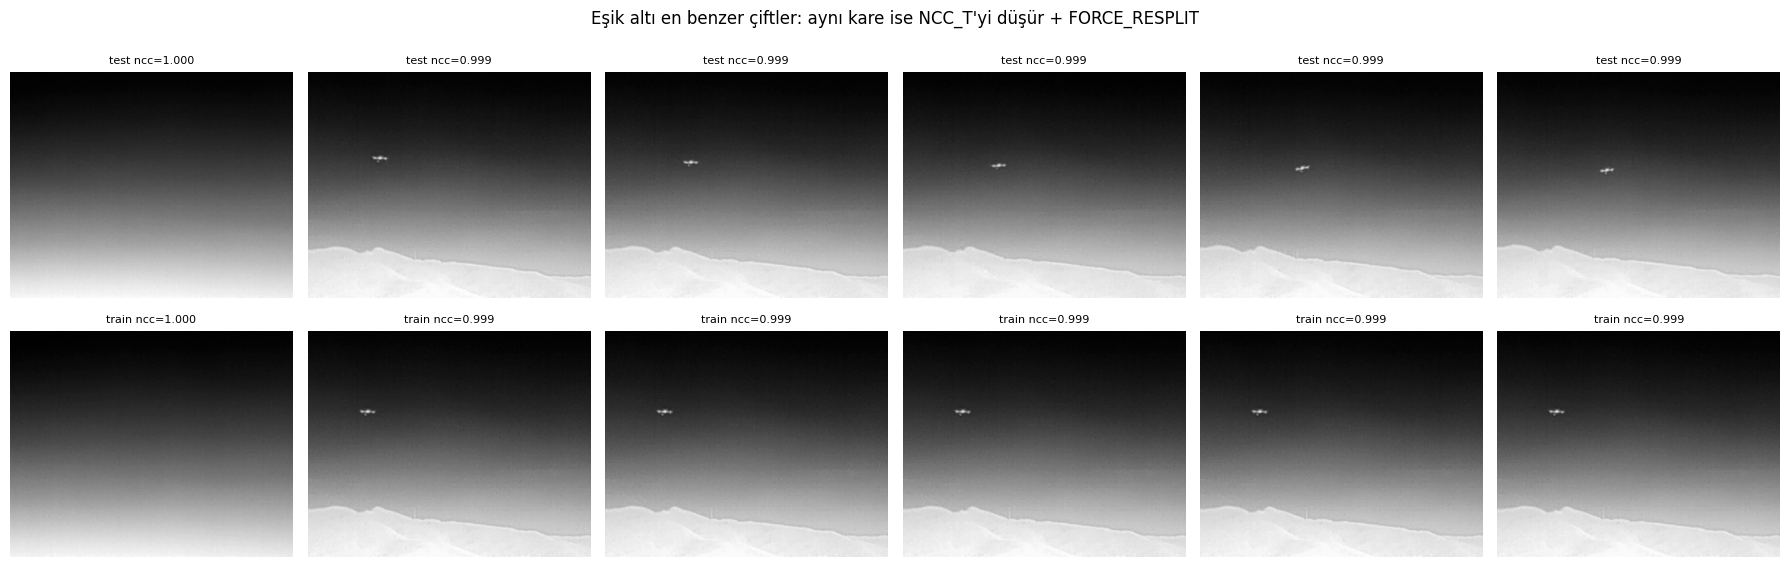


✓ SIZINTI YOK — train/val/test ayrık. Bölme parmak izi: da43dd521edebb0d


In [ ]:
# ==== 4) SIZINTI DENETİMİ (bölmeden bağımsız, sıfırdan hesaplanır) ====
problems = []

# A) Hiçbir yakın-kopya grubu iki kümeye bölünmemeli
gsplits = collections.defaultdict(set)
for k in range(N):
    if SPLIT[k] in RATIOS:
        gsplits[GROUP[k]].add(SPLIT[k])
broken = [g for g, ss in gsplits.items() if len(ss) > 1]
print(f"A) Birden fazla kümeye dağılmış grup     : {len(broken)}")
if broken: problems.append("grup bütünlüğü")

# B) Birebir kopya (MD5) kümeler arasında
md5_splits = collections.defaultdict(set)
for k in range(N):
    if SPLIT[k] in RATIOS:
        md5_splits[MD5[k]].add(SPLIT[k])
n_md5 = sum(len(v) > 1 for v in md5_splits.values())
print(f"B) Kümeler arası birebir kopya (MD5)      : {n_md5}")
if n_md5: problems.append("MD5")

# C) Doğrulanmış yakın kopya (dHash<= {HAM_T} + NCC>= {NCC_T}, D4 dahil) kümeler arasında
cross = [(i, j, v) for i, j, v in PAIRS
         if SPLIT[i] in RATIOS and SPLIT[j] in RATIOS and SPLIT[i] != SPLIT[j]]
print(f"C) Kümeler arası yakın kopya              : {len(cross)}")
if cross: problems.append("yakın kopya")

# D) Bilgi: aynı dosya adı farklı kümelerde (içerik farklıysa sızıntı değildir)
names_by = collections.defaultdict(set)
for k in range(N):
    if SPLIT[k] in RATIOS:
        names_by[os.path.basename(REL[k])].add(SPLIT[k])
print(f"D) (bilgi) farklı kümelerde aynı dosya adı: {sum(len(v) > 1 for v in names_by.values())}")

# E) Bilgi: daha gevşek eşikle val/test -> train en benzer çiftler (görsel kontrol için)
AUDIT_HAM, AUDIT_NCC = 10, 0.90
idx = {s: np.nonzero(SPLIT == s)[0] for s in RATIOS}
loose = []
for q, d in (("val", "train"), ("test", "train"), ("test", "val")):
    pr = near_pairs(idx[q], idx[d], AUDIT_HAM, AUDIT_NCC, desc=f"{q}->{d}")
    loose += pr
    print(f"E) (bilgi) {q}->{d} benzer çift (Ham<={AUDIT_HAM}, NCC>={AUDIT_NCC}): {len(pr)}"
          + (f" | en yüksek NCC: {max(v for *_, v in pr):.3f}" if pr else ""))
if loose:
    import matplotlib.pyplot as plt
    top = sorted(loose, key=lambda x: -x[2])[:6]
    fig, ax = plt.subplots(2, len(top), figsize=(3 * len(top), 6), squeeze=False)
    for c, (i, j, v) in enumerate(top):
        for r, k in enumerate((i, j)):
            ax[r, c].imshow(cv2.imread(os.path.join(DATA_DIR, REL[k]), 0), cmap="gray")
            ax[r, c].set_title(f"{SPLIT[k]} ncc={v:.3f}", fontsize=8); ax[r, c].axis("off")
    plt.suptitle("Eşik altı en benzer çiftler: aynı kare ise NCC_T'yi düşür + FORCE_RESPLIT"); plt.tight_layout(); plt.show()

if problems:
    raise AssertionError(f"SIZINTI VAR: {problems}. Bölme ile mevcut eşikler uyuşmuyor; FORCE_RESPLIT=True ile yeniden böl.")
print(f"\n✓ SIZINTI YOK — train/val/test ayrık. Bölme parmak izi: {FP}")

## 4. Eğitim

In [ ]:
# ==== 5) EĞİTİM (yalnız train/val kullanılır; test'e dokunulmaz) ====
from ultralytics import YOLO

RUN_NAME = "uav_thermal_6cls"
LOCAL_PROJECT = "/content/runs"
DRIVE_RUNS = os.path.join(DRIVE_ROOT, "runs")

model = YOLO("yolov8n.pt")       # daha yüksek doğruluk için "yolov8s.pt"
model.train(
    data=DATA_YAML, epochs=25, imgsz=640, batch=32, patience=10, device=0, workers=4,
    cache=False, project=LOCAL_PROJECT, name=RUN_NAME, exist_ok=True,
    seed=SEED, deterministic=True, plots=True,
)

run_dir = str(model.trainer.save_dir)
shutil.copy2(INFO, os.path.join(run_dir, "split_info.json"))   # ağırlık hangi bölmeyle eğitildi -> kanıt
dst = os.path.join(DRIVE_RUNS, RUN_NAME)
shutil.rmtree(dst, ignore_errors=True)
shutil.copytree(run_dir, dst)
print(f"Eğitim çıktıları Drive'a kopyalandı: {dst}")
print(f"Test değerlendirmesi için: test_degerlendirme.ipynb (WEIGHTS = {dst}/weights/best.pt)")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/work/data_6cls.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, f

## 5. Test
Test kümesi değerlendirmesi **`test_degerlendirme.ipynb`** dosyasındadır (aynı Drive bölmesini kullanır).